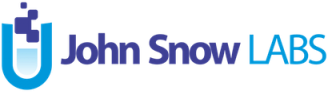

# 🚀 JohnSnowLabs Medical-DM-Small and PHI Guards

This notebook shows the endpoints of a `Medical-DM-Small` container started with PHI guards: what you send, what comes back, and how to read it.
All notes in this notebook are invented.

| Endpoint | What it does |
|----------|--------------|
| `GET /health`, `GET /v1/models` | Is the server ready, and which decision model it serves. |
| `GET /v1/guards` | The guards loaded in the container. |
| `POST /v1/guards` (experimental) | Checks documents with one guard: is PHI left in a de-identified note, is it harmful, how much PHI, does a raw note hold PHI. Runs on the CPU. |
| `POST /v1/guards/ensemble` (experimental) | Checks documents with a guard **and** with `Medical-DM-Small`, combines the two scores, and routes each document to `leak`, `review` or `clean`. |
| `POST /v1/decisions` | Asks the decision model typed questions (yes/no, choice, score) about a text. |

### 🔄 Pull the Docker Image

You can pull the image from 👉 [Docker Hub](https://hub.docker.com/r/johnsnowlabs/jsl-llms):

```bash
docker pull johnsnowlabs/jsl-llms:0.33.0
```

---

### 🐳 Run the Container

Make sure to set your license key:

```bash
export SPARK_NLP_LICENSE=your_license_key_here
```

Then run the container with the decision model and the guards:

```bash
docker run -d \
    --gpus all \
    --env "SPARK_NLP_LICENSE=$SPARK_NLP_LICENSE" \
    -p 8080:8080 \
    --ipc=host \
    johnsnowlabs/jsl-llms:0.33.0 \
    --model Medical-DM-Small \
    --guards all \
    --port 8080
```

`--guards` takes `all`, or guard ids separated by commas (for example `--guards phi-guard-v7-fast`). Without it the guard endpoints are not active.

---

### 📜 View Container Logs

```bash
docker logs <container-id>
```

The service is ready when `GET /health` answers `ok`. Loading the model takes a few minutes. 🎉

## Install Required Packages

In [ ]:
%pip install -q requests pandas

## Imports and helpers
`call()` sends a request and returns the status and the JSON answer. `show()` also prints what was sent. Set the environment variable `BASE_URL` if the container is not on `http://localhost:8080`.

In [1]:
import json
import os

import pandas as pd
import requests

BASE_URL = os.environ.get("BASE_URL", "http://localhost:8080")


def call(method, path, payload=None):
    """Send a request to the container and return (HTTP status, JSON answer)."""
    response = requests.request(method, BASE_URL + path, json=payload, timeout=300)
    return response.status_code, response.json()


def show(method, path, payload=None):
    """Send a request and print the payload and the answer."""
    if payload is not None:
        print("payload:")
        print(json.dumps(payload, indent=2, ensure_ascii=False))
    status, answer = call(method, path, payload)
    print(f"\n{method} {path} -> HTTP {status}")
    print(json.dumps(answer, indent=2, ensure_ascii=False))
    return answer

## Check the server
`/health` says the server is ready. `/v1/models` lists only the decision model: guards are not chat models. `/v1/guards` lists the guards that were loaded.

In [2]:
print("health:", call("GET", "/health")[1])
print("models:", [m["id"] for m in call("GET", "/v1/models")[1]["data"]])

guards = call("GET", "/v1/guards")[1]["data"]
pd.DataFrame([{"id": g["id"], "task": g["task"], "cut-off": g["default_cutoff"]} for g in guards]).set_index("id")

health: {'status': 'ok', 'model': 'Medical-DM-Small'}
models: ['Medical-DM-Small']


,task,cut-off
id,,
phi-guard-v7-final,harm+richness+raw,0.5
phi-guard-v7-fast,harm+richness+raw,0.5


## 🛡️ Guards (experimental): is PHI left in a note?

A guard reads whole documents and returns four answers in one call. Every label uses the cut-off 0.5.

| Answer | Fields | Meaning | Use it on |
|--------|--------|---------|-----------|
| **Leak** | `score`, `logit`, `label` | Probability that real PHI is still readable in a de-identified note. | De-identified text |
| **Harmful leak** | `harmful_score`, `harmful_logit`, `harmful_label` | Probability that the leak is harmful (a name, ID, contact detail, date of birth, street address, an age over 89). Never above `score`. | De-identified text |
| **Exposure level** | `level`, `expected_level`, `level_scores`, `level_logits` | How much PHI a note shows, from 0 to 6: none, trace, low, moderate, high, very high, saturated. | Either |
| **Raw note** | `raw_score`, `raw_logit`, `raw_label` | Probability that a raw note, before de-identification, holds PHI at all. | Raw text |

These are PHI guards v0.7 (experimental, still under test): `phi-guard-v7-final` (best accuracy) and `phi-guard-v7-fast` (the same outputs, about 5 times faster, a little less accurate).

**What to send:** masked or raw documents. Do not send an obfuscated copy (real PHI replaced by realistic fake names, dates and numbers): it looks like real PHI to the guard and raises false flags.


### Score documents: `POST /v1/guards`
Send the guard in `model` and a list of `docs`. Every document needs a unique `id` of your choice and a string `text`. The results come back in the same order. `phi-guard-v7-final` is the best choice; send `phi-guard-v7-fast` as `model` when speed matters more.

In [3]:
CLEAN = "Pt [NAME] seen on [DATE] for chest pain. Troponin negative x2, ECG normal sinus rhythm. Discharged home on aspirin 81 mg daily."
LEAK = "Pt Maria Delgado, DOB 03/14/1956, MRN 4471923, seen on [DATE] for chest pain. Discharged home on aspirin 81 mg daily."

answer = show("POST", "/v1/guards", {
    "model": "phi-guard-v7-final",
    "docs": [{"id": "note-001", "text": CLEAN}, {"id": "note-002", "text": LEAK}],
})

payload:
{
  "model": "phi-guard-v7-final",
  "docs": [
    {
      "id": "note-001",
      "text": "Pt [NAME] seen on [DATE] for chest pain. Troponin negative x2, ECG normal sinus rhythm. Discharged home on aspirin 81 mg daily."
    },
    {
      "id": "note-002",
      "text": "Pt Maria Delgado, DOB 03/14/1956, MRN 4471923, seen on [DATE] for chest pain. Discharged home on aspirin 81 mg daily."
    }
  ]
}

POST /v1/guards -> HTTP 200
{
  "model": "phi-guard-v7-final",
  "default_cutoff": 0.5,
  "results": [
    {
      "id": "note-001",
      "score": 0.0101,
      "logit": -4.5816,
      "label": false,
      "cutoffs": {
        "0.5": false
      },
      "harmful_score": 0.0028,
      "harmful_logit": -5.8852,
      "harmful_label": false,
      "level": 0,
      "expected_level": 0.0002,
      "level_scores": [
        0.0001,
        0.0001,
        0.0,
        0.0,
        0.0,
        0.0
      ],
      "level_logits": [
        -9.3833,
        -9.3833,
        -13.0165,


**Reading it:** `note-001` has every identifier masked, so `score` is close to 0 and `label` is `false`. `note-002` still shows a name, a date of birth and a record number: `score` is close to 1, `label` and `harmful_label` are `true`, and the level is higher than 0.
`usage` says how many documents and windows were read (long texts are read in 1,024-byte windows) and how long it took in milliseconds. Very sure scores all round to 1.0: to rank notes, use the `logit` fields.

The same fields and values as the JSON above, one row per document (`level_name` is the name of the `level`).

In [4]:
LEVELS = ["none", "trace", "low", "moderate", "high", "very high", "saturated"]


def guard_table(answer):
    """One row per document, with the field names of the answer."""
    rows = []
    for r in answer["results"]:
        rows.append({
            "id": r["id"],
            "score": r["score"], "label": r["label"],
            "harmful_score": r["harmful_score"], "harmful_label": r["harmful_label"],
            "level": r["level"], "level_name": LEVELS[r["level"]],
            "raw_score": r["raw_score"],
        })
    return pd.DataFrame(rows).set_index("id")


guard_table(answer)

,score,label,harmful_score,harmful_label,level,level_name,raw_score
id,,,,,,,
note-001,0.0101,False,0.0028,False,0,none,0.0
note-002,1.0000,True,1.0000,True,3,moderate,1.0


### Long notes
A long text is read in overlapping 1,024-byte windows and the answer covers the whole note. Here a leak sits at the very end of a 3 KB note.

In [5]:
long_note = ("Pt [NAME] seen on [DATE] for chest pain; labs stable, meds unchanged. " * 45)[:3000] + " Maria Delgado, MRN 4471923."
_, answer = call("POST", "/v1/guards", {"model": "phi-guard-v7-final", "docs": [{"id": "long note", "text": long_note}]})
print("characters:", len(long_note), "| windows read:", answer["usage"]["windows"])
guard_table(answer)

characters: 3028 | windows read: 4


,score,label,harmful_score,harmful_label,level,level_name,raw_score
id,,,,,,,
long note,1.0,True,0.9846,True,2,low,1.0


### Raw notes
For a raw note (not yet de-identified) look at `raw_score` and the level: `raw_score` tells whether the note holds PHI at all, so you can skip notes that need no de-identification. The leak columns are meant for de-identified text.

In [6]:
raw_docs = [
    {"id": "raw note with PHI", "text": "John Miller, 64, was seen on 2024-02-11 at St. Luke's for shortness of breath. Contact: 555-201-3344."},
    {"id": "raw note without PHI", "text": "Shortness of breath on exertion, improved with albuterol. Lungs clear on auscultation. Continue current inhaler regimen."},
]
_, answer = call("POST", "/v1/guards", {"model": "phi-guard-v7-final", "docs": raw_docs})
guard_table(answer)[["raw_score", "level", "level_name"]]

,raw_score,level,level_name
id,,,
raw note with PHI,1.0,4,high
raw note without PHI,0.0,0,none


## ⚖️ Ensemble (experimental): a guard and the decision model together

`POST /v1/guards/ensemble` checks each document with a guard **and** with `Medical-DM-Small`, then combines the two scores. The combined score ranks leaks better than either model alone, and the route sends only the disagreements to a person:

| `decision` | Meaning |
|------------|---------|
| `leak` | Both models flag the document. |
| `review` | Only one model flags it: send it to a person. |
| `clean` | Neither flags it. |

| Request field | |
|---------------|---|
| `model` | `phi-guard-ensemble`. Required. |
| `docs` | Up to 64 documents. Required. |
| `guard` | Optional. A loaded guard with a harmful output. Default: the first guard of `GET /v1/guards`. The answer names the guard that was used. |
| `aggregation` | Optional. How the two scores are combined: `mean_logit` (default, best ranking), `mean`, `min` or `max`. |
| `decision` | Optional. `Medical-DM-Small`: a container serves one decision model. |

The shortest request has only `model` and `docs`:

In [7]:
answer = show("POST", "/v1/guards/ensemble", {
    "model": "phi-guard-ensemble",
    "docs": [{"id": "note-001", "text": CLEAN}, {"id": "note-002", "text": LEAK}],
})

payload:
{
  "model": "phi-guard-ensemble",
  "docs": [
    {
      "id": "note-001",
      "text": "Pt [NAME] seen on [DATE] for chest pain. Troponin negative x2, ECG normal sinus rhythm. Discharged home on aspirin 81 mg daily."
    },
    {
      "id": "note-002",
      "text": "Pt Maria Delgado, DOB 03/14/1956, MRN 4471923, seen on [DATE] for chest pain. Discharged home on aspirin 81 mg daily."
    }
  ]
}

POST /v1/guards/ensemble -> HTTP 200
{
  "model": "phi-guard-ensemble",
  "guard": "phi-guard-v7-final",
  "aggregation": "mean_logit",
  "results": [
    {
      "id": "note-001",
      "score": 0.001,
      "logit": -6.8959,
      "label": false,
      "harmful_score": 0.0005,
      "harmful_logit": -7.5477,
      "harmful_label": false,
      "decision": "clean",
      "agreement": true,
      "members": {
        "guard_score": 0.0101,
        "guard_harmful_score": 0.0028,
        "decision_score": 0.0
      },
      "level": 0,
      "level_scores": [
        0.0001,
      

**Reading it:** `guard` names the guard that ran. `members` has the score of each model (`guard_score`, `guard_harmful_score`, `decision_score`). `score`, `logit` and `label` are the **combined** leak result, `harmful_*` the combined harmful result, and `decision` the route. `usage.decision_calls` counts how often the decision model was asked.

In [8]:
def ensemble_table(answer):
    rows = []
    for r in answer["results"]:
        rows.append({
            "id": r["id"], "guard": r["members"]["guard_score"], "decision model": r["members"]["decision_score"],
            "combined": r["score"], "route": r["decision"], "agree": r["agreement"],
        })
    return pd.DataFrame(rows).set_index("id")


ensemble_table(answer)

,guard,decision model,combined,route,agree
id,,,,,
note-001,0.0101,0.0,0.001,clean,True
note-002,1.0000,1.0,1.000,leak,True


### Aggregations
The aggregation changes the combined score, not the route (the route comes from each model's own flag). `mean_logit` averages the scores before they become probabilities, so a very sure model is not capped at 1.0. `min` needs both models to be sure that PHI is left, `max` needs only one.

In [9]:
note = [{"id": "93-year-old patient", "text": "A 93-year-old patient was admitted on [DATE] with a hip fracture after a fall at home. Surgery planned for tomorrow."}]
rows = []
for how in ("mean_logit", "mean", "min", "max"):
    _, answer = call("POST", "/v1/guards/ensemble", {"model": "phi-guard-ensemble", "aggregation": how, "docs": note})
    r = answer["results"][0]
    rows.append({"aggregation": how, "combined score": r["score"], "route": r["decision"],
                 "guard": r["members"]["guard_score"], "decision model": r["members"]["decision_score"]})
pd.DataFrame(rows).set_index("aggregation")

,combined score,route,guard,decision model
aggregation,,,,
mean_logit,0.7206,review,0.9986,0.009
mean,0.5038,review,0.9986,0.009
min,0.0090,review,0.9986,0.009
max,0.9986,review,0.9986,0.009


### Bring your own decision score
A document can carry a `decision_score` (a probability from 0 to 1). It is then not sent to the decision model, and `usage.decision_calls` counts only the other documents. Useful when you already have the score.

In [10]:
_, answer = call("POST", "/v1/guards/ensemble", {
    "model": "phi-guard-ensemble",
    "guard": "phi-guard-v7-fast",                  # optional: choose the guard
    "docs": [
        {"id": "with my own score", "text": LEAK, "decision_score": 0.97},   # brings its own score: the decision model is not asked
        {"id": "asked the model", "text": CLEAN},                            # no score: the decision model is asked
    ],
})
print("the decision model was asked for", answer["usage"]["decision_calls"], "of 2 documents | guard used:", answer["guard"])
ensemble_table(answer)

the decision model was asked for 1 of 2 documents | guard used: phi-guard-v7-fast


,guard,decision model,combined,route,agree
id,,,,,
with my own score,1.0000,0.97,0.9999,leak,True
asked the model,0.0205,0.00,0.0014,clean,True


## 🧼 Get a masked note with the JSL de-identification pipeline
The guards check masked or raw text. To mask a raw note, run it through the JSL de-identification pipeline `clinical_deidentification_docwise_wip` and rebuild the note from the masked pieces. Do not send the `obfuscated` output to the guards.

An example of a masked note, typed in so that the rest of this notebook runs without Spark. If you run the pipeline below, its result replaces it:

In [11]:
masked_note = "Name: <PATIENT>, MRN <MEDICALRECORD>, seen on <DATE> by Dr. <DOCTOR> at <HOSPITAL>.\nPhone <PHONE>. Chest pain resolved, discharged home on aspirin 81 mg daily."
print(masked_note)

Name: <PATIENT>, MRN <MEDICALRECORD>, seen on <DATE> by Dr. <DOCTOR> at <HOSPITAL>.
Phone <PHONE>. Chest pain resolved, discharged home on aspirin 81 mg daily.


In [ ]:
%pip install -q johnsnowlabs

In [ ]:
from ipywidgets import FileUpload
from IPython.display import display

license_upload = FileUpload(accept=".json", multiple=False, description="License")
display(license_upload)

In [13]:
value = license_upload.value
uploaded = value[0] if isinstance(value, (tuple, list)) else next(iter(value.values()))
with open("license.json", "wb") as f:
    f.write(bytes(uploaded["content"]))

In [ ]:
from johnsnowlabs import nlp

nlp.install(json_license_path="license.json")
spark = nlp.start()

In [ ]:
deid = nlp.PretrainedPipeline("clinical_deidentification_docwise_wip", "en", "clinical/models")

In [16]:
raw_note = ("Name: Marie Dupont, MRN 5521873, seen on 03/14/2024 by Dr. Alan Brooks at St. Mary's Hospital.\n"
            "Phone (415) 555-0142. Chest pain resolved, discharged home on aspirin 81 mg daily.")


def mask_text(text, res):
    """Rebuild the masked note: the original text between the pieces, and the masked piece in place of each piece."""
    out, start = "", 0
    for piece, masked in zip(res["document"], res["mask_entity"]):
        out += text[start:piece.begin] + masked.result
        start = piece.end + 1
    return out.strip()


res = deid.fullAnnotate(raw_note)[0]
masked_note = mask_text(raw_note, res)
print(masked_note)

Name: <PATIENT>, MRN <MEDICALRECORD>, seen on <DATE> by Dr. <DOCTOR> at <HOSPITAL>.
Phone <PHONE>. Chest pain resolved, discharged home on aspirin 81 mg daily.


Send the masked note to the guard and to the ensemble:

In [17]:
_, answer = call("POST", "/v1/guards", {"model": "phi-guard-v7-final", "docs": [{"id": "masked note", "text": masked_note}]})
guard_table(answer)

,score,label,harmful_score,harmful_label,level,level_name,raw_score
id,,,,,,,
masked note,0.0009,False,0.0001,False,0,none,0.0


In [18]:
_, answer = call("POST", "/v1/guards/ensemble", {"model": "phi-guard-ensemble", "docs": [{"id": "masked note", "text": masked_note}]})
r = answer["results"][0]
print("route:", r["decision"], "| combined score:", r["score"], "| guard:", r["members"]["guard_score"], "| decision model:", r["members"]["decision_score"])

route: clean | combined score: 0.0003 | guard: 0.0009 | decision model: 0.0001


## 🧠 Decision model: typed questions

`POST /v1/decisions` does not write text. It reads one record (`state`) and up to 64 typed questions, and returns a probability for every option.

| Question `type` | Answer | `criteria` |
|-----------------|--------|------------|
| `noul` | Yes or no. Returns `noul`, the probability of yes. | Optional `{"true": "...", "false": "..."}` definitions. |
| `choice` | Pick one option. Returns `choice`, `confidence` and `probabilities`. | Object of option key to description. |
| `score` | An ordered level. Returns the expected `score` and a probability per level. | List of level descriptions, in order. |

In [19]:
answer = show("POST", "/v1/decisions", {
    "model": "Medical-DM-Small",
    "state": "Discharge summary. Patient Alder Quill was admitted with chest pain. Troponin normal; discharged home on aspirin.",
    "questions": {
        "leak": {
            "type": "noul",
            "instructions": "Is any real identifying detail left in this de-identified note?",
            "criteria": {"true": "A real name, phone number, address, date or record number appears in the text",
                         "false": "Every identifier is a tag such as [NAME] or [DATE], or has been removed"},
        },
        "kind": {
            "type": "choice",
            "instructions": "Which kind of real identifier is left in the note?",
            "criteria": {"person_name": "A real person name (a tag like [NAME] does not count)",
                         "phone_number": "A real telephone number",
                         "none": "No real identifier: only tags such as [NAME] or [DATE]"},
        },
        "how_many": {
            "type": "score",
            "instructions": "How many real identifiers are left in the note?",
            "criteria": ["none", "one", "two or more"],
        },
    },
})

payload:
{
  "model": "Medical-DM-Small",
  "state": "Discharge summary. Patient Alder Quill was admitted with chest pain. Troponin normal; discharged home on aspirin.",
  "questions": {
    "leak": {
      "type": "noul",
      "instructions": "Is any real identifying detail left in this de-identified note?",
      "criteria": {
        "true": "A real name, phone number, address, date or record number appears in the text",
        "false": "Every identifier is a tag such as [NAME] or [DATE], or has been removed"
      }
    },
    "kind": {
      "type": "choice",
      "instructions": "Which kind of real identifier is left in the note?",
      "criteria": {
        "person_name": "A real person name (a tag like [NAME] does not count)",
        "phone_number": "A real telephone number",
        "none": "No real identifier: only tags such as [NAME] or [DATE]"
      }
    },
    "how_many": {
      "type": "score",
      "instructions": "How many real identifiers are left in the note?"

**Reading it:** `leak` (`noul`) is the probability that the answer is yes. `kind` (`choice`) gives the most likely option, a probability for every option, and a `confidence` that rescales the top probability against chance: send low-confidence answers to a person. `how_many` (`score`) gives the expected level (0 = none, 1 = one, 2 = two or more) and a probability per level. `usage` counts the tokens.

## 🔎 Screen many notes

Put it together: check a list of notes with the ensemble, 64 per request, and send the disagreements to a person.

In [20]:
def screen(notes, guard=None, chunk=64):
    """Check many notes with the ensemble and return one row per note."""
    ids = list(notes)
    rows = []
    for start in range(0, len(ids), chunk):
        docs = [{"id": i, "text": notes[i]} for i in ids[start:start + chunk]]
        payload = {"model": "phi-guard-ensemble", "docs": docs}
        if guard:
            payload["guard"] = guard
        _, answer = call("POST", "/v1/guards/ensemble", payload)
        for r in answer["results"]:
            rows.append({"id": r["id"], "route": r["decision"], "combined": r["score"], "harmful?": r["harmful_label"],
                         "guard": r["members"]["guard_score"], "decision model": r["members"]["decision_score"]})
    return pd.DataFrame(rows).set_index("id")


notes = {
    "masked": CLEAN,
    "tags only": "[NAME], a [AGE]-year-old from [LOCATION], was admitted on [DATE] to [HOSPITAL] with abdominal pain. CT showed appendicitis.",
    "no PHI": "Shortness of breath on exertion, improved with albuterol. Lungs clear on auscultation. Continue current inhaler regimen.",
    "name, date of birth and record number left": LEAK,
    "phone number left": "Discharged home. Follow up with [NAME] at 555-0142 in two weeks. Continue metformin 500 mg twice daily.",
    "e-mail address left": "Results were sent to jane.doe@example.org on [DATE]. Pt [NAME] to repeat labs in 3 months. No medication changes.",
    "member id left": "Pt [NAME], member ID 88213-04, seen on [DATE] for routine follow up. Vitals stable. Continue current medications.",
    "93-year-old patient": "A 93-year-old patient was admitted on [DATE] with a hip fracture after a fall at home. Surgery planned for tomorrow.",
}
result = screen(notes)
print(result["route"].value_counts().to_string())
result

route
leak      4
clean     3
review    1


,route,combined,harmful?,guard,decision model
id,,,,,
masked,clean,0.0010,False,0.0101,0.0000
tags only,clean,0.0003,False,0.0009,0.0000
no PHI,clean,0.0003,False,0.0009,0.0000
"name, date of birth and record number left",leak,1.0000,True,1.0000,1.0000
phone number left,leak,0.9998,True,0.9999,0.9994
e-mail address left,leak,0.9995,True,0.9978,1.0000
member id left,leak,0.9999,True,1.0000,1.0000
93-year-old patient,review,0.7206,False,0.9986,0.0090


In [21]:
# the notes where the two models disagree go to a person
result[result["route"] == "review"]

,route,combined,harmful?,guard,decision model
id,,,,,
93-year-old patient,review,0.7206,False,0.9986,0.009


## Errors

A request that cannot be answered returns an HTTP status and a `detail` message.

| Status | When |
|--------|------|
| `400` | The body is not valid JSON, `docs` is empty, a document has no string `text`, ids are not unique, or a field has a wrong value. |
| `404` | Unknown guard or unknown ensemble name. Also the answer of the guard endpoints when the container was started without `--guards`. |
| `413` | More than 16,384 documents (64 for the ensemble), or a body over 50 MiB. |
| `422` | A document is too long for the decision model (16,384 tokens), or an invalid `/v1/decisions` request. |
| `502`, `503`, `504` | The decision model failed, is not ready, or timed out. The ensemble never returns one model's score alone. |

In [22]:
for label, payload in {
    "unknown guard": {"model": "phi-guard-v9", "docs": [{"id": "a", "text": "x"}]},
    "empty docs": {"model": "phi-guard-v7-final", "docs": []},
    "document without text": {"model": "phi-guard-v7-final", "docs": [{"id": "a"}]},
    "duplicate ids": {"model": "phi-guard-v7-final", "docs": [{"id": "a", "text": "x"}, {"id": "a", "text": "y"}]},
}.items():
    status, answer = call("POST", "/v1/guards", payload)
    print(f"{label:24s} -> HTTP {status}: {answer['detail']}")

unknown guard            -> HTTP 404: The guard model 'phi-guard-v9' does not exist
empty docs               -> HTTP 400: docs must be a non-empty list
document without text    -> HTTP 400: every doc needs a string 'text'
duplicate ids            -> HTTP 400: doc ids must be unique


## 📘 API reference

The container serves an interactive API reference of all these endpoints:

```
http://localhost:8080/openapi-doc
```

Each POST endpoint there has a working example, and every endpoint has a **Test Request** button. The raw OpenAPI document is at `/openapi.json`. The page loads its viewer and fonts from the internet in your browser (`cdn.jsdelivr.net` and Google Fonts): without internet access, use `/openapi.json`.

## Limits

| | |
|--|--|
| `POST /v1/guards` | Up to 16,384 documents and 50 MiB per request. |
| `POST /v1/guards/ensemble` | Up to 64 documents per request. Each document must fit the decision model (16,384 tokens). |
| `POST /v1/decisions` | Up to 64 questions. The record, one question and its options must fit 16,384 tokens. |
| Document ids | Unique within a request, any JSON value. They come back unchanged. |